# W11D1 — Data Storytelling: Structure and Narrative

**Project:** EDA on Indian Business Dataset

**Business question:** Which product categories generate strong sales,
and are those sales translating into profit?

**Story structure:** Context → Finding → Evidence → Meaning → Action

This notebook uses transaction data from April 2018 to March 2019.


## 1. Context — Understanding business performance

A business needs more than sales growth. It also needs profitable sales.

We will compare sales, profit and profit margins across product
categories to identify areas that deserve further investigation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("data/indian_business_orders.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"])

print("Dataset shape:", df.shape)
print("Date range:", df["Order Date"].min().date(),
      "to", df["Order Date"].max().date())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.head())


Dataset shape: (1500, 17)
Date range: 2018-04-01 to 2019-03-31
Missing values: 0
Duplicate rows: 0


,Order ID,Order Date,CustomerName,State,City,Amount,Profit,Quantity,Category,Sub-Category,Year,Month,Month_Name,Quarter,Day,Weekday,Weekday_Name
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,1275.0,-1148.0,7,Furniture,Bookcases,2018,4,Apr,2,1,6,Sunday
1,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,66.0,-12.0,5,Clothing,Stole,2018,4,Apr,2,1,6,Sunday
2,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,8.0,-2.0,3,Clothing,Hankerchief,2018,4,Apr,2,1,6,Sunday
3,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,80.0,-56.0,4,Electronics,Electronic Games,2018,4,Apr,2,1,6,Sunday
4,B-25602,2018-04-01,Pearl,Maharashtra,Pune,168.0,-111.0,2,Electronics,Phones,2018,4,Apr,2,1,6,Sunday


## 2. Key business metrics

These KPIs establish the overall business picture.

**Profit margin** = Total Profit ÷ Total Sales × 100.


In [2]:
total_sales = df["Amount"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
profit_margin = 100 * total_profit / total_sales

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Unique Orders: {total_orders}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")


Total Sales: ₹431,502.00
Total Profit: ₹23,955.00
Unique Orders: 500
Overall Profit Margin: 5.55%


## 3. Finding — Sales and profit tell different stories

Our central question is whether categories with high sales
also deliver strong profitability.


In [3]:
category = (
    df.groupby("Category", as_index=False)
      .agg(Sales=("Amount", "sum"), Profit=("Profit", "sum"))
)
category["Profit Margin (%)"] = (
    100 * category["Profit"] / category["Sales"]
)
display(category.round(2))


,Category,Sales,Profit,Profit Margin (%)
0,Clothing,139054.0,11163.0,8.03
1,Electronics,165267.0,10494.0,6.35
2,Furniture,127181.0,2298.0,1.81


## 4. Evidence — Visual comparison

The first chart compares sales and profit by category.
The second chart compares profit margins.

These charts use descriptive titles and direct value labels
to make the message understandable to business stakeholders.


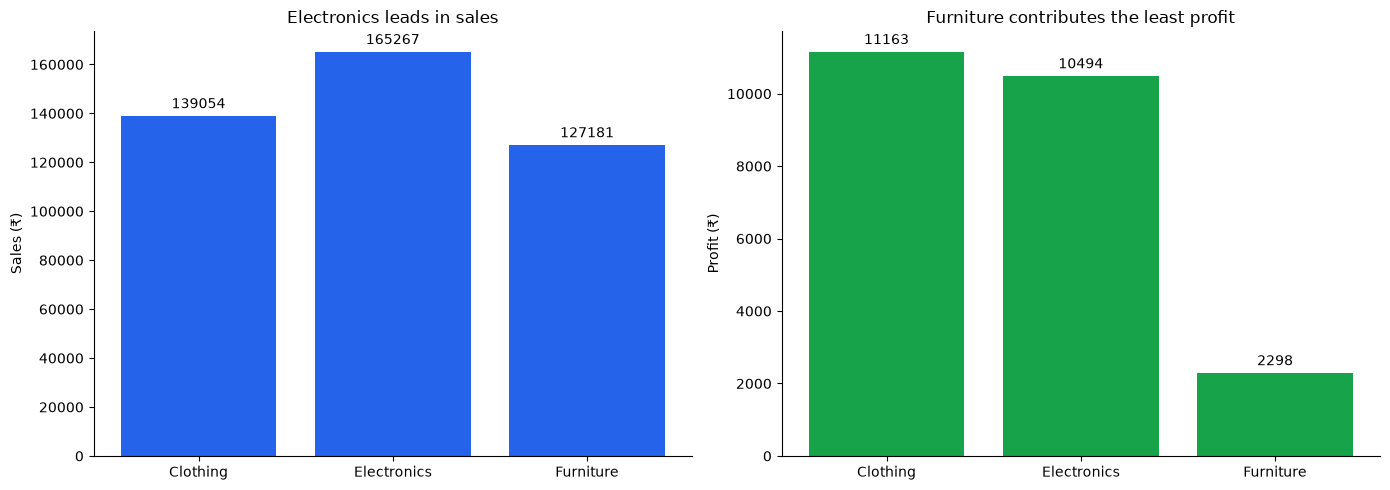

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars1 = axes[0].bar(
    category["Category"], category["Sales"],
    color="#2563eb"
)
axes[0].set_title("Electronics leads in sales")
axes[0].set_ylabel("Sales (₹)")
axes[0].bar_label(bars1, fmt="%.0f", padding=3)
axes[0].spines[["top", "right"]].set_visible(False)

bars2 = axes[1].bar(
    category["Category"], category["Profit"],
    color="#16a34a"
)
axes[1].set_title("Furniture contributes the least profit")
axes[1].set_ylabel("Profit (₹)")
axes[1].bar_label(bars2, fmt="%.0f", padding=3)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/w11d1_sales_profit.png", dpi=160,
            bbox_inches="tight")
plt.show()


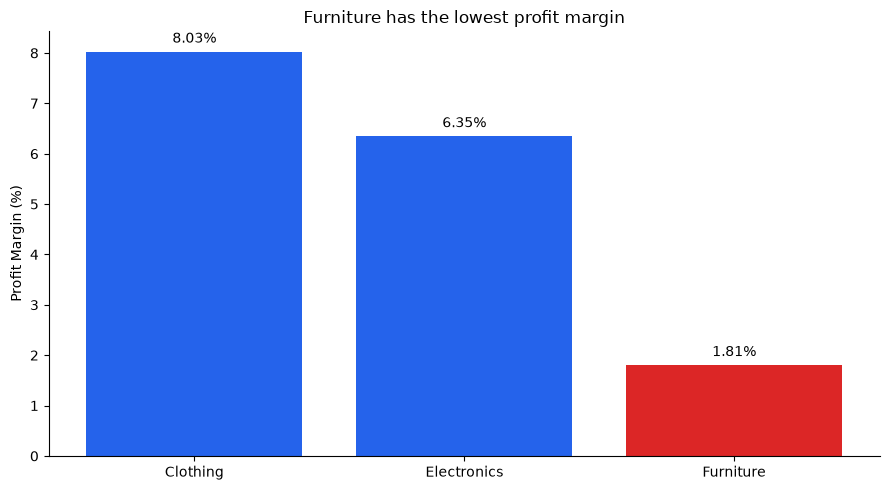

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    "#dc2626" if name == "Furniture" else "#2563eb"
    for name in category["Category"]
]

bars = ax.bar(
    category["Category"],
    category["Profit Margin (%)"],
    color=colors
)
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set_ylabel("Profit Margin (%)")
ax.set_title("Furniture has the lowest profit margin")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("outputs/w11d1_profit_margin.png", dpi=160,
            bbox_inches="tight")
plt.show()


## 5. Meaning — Interpret the findings

The results show:

- **Electronics** generates the highest sales.
- **Clothing** generates the highest total profit.
- **Furniture** has the lowest profit and profit margin.

Furniture's low margin suggests an opportunity for investigation,
but this analysis does not establish the cause.


In [6]:
for _, row in category.sort_values(
    "Profit Margin (%)", ascending=False
).iterrows():
    print(
        f"{row['Category']}: "
        f"Sales ₹{row['Sales']:,.0f}, "
        f"Profit ₹{row['Profit']:,.0f}, "
        f"Margin {row['Profit Margin (%)']:.2f}%"
    )


Clothing: Sales ₹139,054, Profit ₹11,163, Margin 8.03%
Electronics: Sales ₹165,267, Profit ₹10,494, Margin 6.35%
Furniture: Sales ₹127,181, Profit ₹2,298, Margin 1.81%


## 6. Action — Business recommendations

1. **Investigate Furniture profitability:** Review sub-category
   margins, discounts, returns and costs if available.
2. **Study Clothing's stronger margins:** Identify practices that
   may be transferable to other categories.
3. **Monitor Electronics:** Track both sales and profit instead
   of using revenue alone as the performance measure.
4. **Create a monthly profitability review:** Compare sales,
   profit and margin by category over time.

These are investigation priorities, not proven causal explanations.


## 7. Limitations and responsible storytelling

- The dataset covers **April 2018 to March 2019** only.
- Category-level aggregation can hide differences among products.
- The dataset does not establish why a category has a low margin.
- Findings describe this dataset and should not automatically
  be generalized to the entire Indian retail market.
- Additional cost, discount and operational data would help
  test explanations for profitability differences.


## 8. Final stakeholder narrative

**Context:** The business generated substantial sales across three
product categories, but sales alone cannot measure success.

**Finding:** Furniture generated meaningful revenue while delivering
the weakest profit margin.

**Evidence:** Category-level sales, profit and margin comparisons.

**Meaning:** Revenue contribution and profitability differ, so
business decisions should consider both.

**Action:** Prioritize a detailed Furniture profitability review,
while monitoring all categories through a recurring KPI dashboard.

**Core lesson:** A good data story connects a clear question,
reliable evidence, interpretation and a practical next step.
